In [1]:
import pandas as pd
import matplotlib.pyplot as plt # visualization library

In [2]:
exports = pd.read_excel("../data/N9133US2m.xls") # this command reads the first sheet in the excel file by default

In [3]:
exports.head() # displays the first 5 rows of the data frame so we can quickly get an idea what's in the excel file

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,NaN,Workbook Contents,NaN,NaN,NaN,NaN
1,NaN,Liquefied U.S. Natural Gas Exports (MMcf),NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,Click worksheet name or tab at bottom for data,NaN,NaN,NaN,NaN
4,NaN,Worksheet Name,Description,# Of Series,Frequency,Latest Data for


In [4]:
pd.ExcelFile("../data/N9133US2m.xls").sheet_names # pd.ExcelFile(...) tells pandas to treat the file as an Excel workbook rather than one sheet

['Contents', 'Data 1']

In [5]:
exports = pd.read_excel("../data/N9133US2m.xls", sheet_name="Data 1") # now we know the data we want to manipulate is stored in sheet "Data 1"

In [6]:
exports.head()

,Back to Contents,Data 1: Liquefied U.S. Natural Gas Exports (MMcf)
0,Sourcekey,N9133US2
1,Date,Liquefied U.S. Natural Gas Exports (MMcf)
2,1997-01-15 00:00:00,5604
3,1997-02-15 00:00:00,5596
4,1997-03-15 00:00:00,5675


In [7]:
exports = pd.read_excel("../data/N9133US2m.xls",sheet_name="Data 1",header=2) # with header=2 we're actually saying "Don't treat Excel's first row as the column headers. The actual headers are on the third row."
exports.head()

,Date,Liquefied U.S. Natural Gas Exports (MMcf)
0,1997-01-15,5604
1,1997-02-15,5596
2,1997-03-15,5675
3,1997-04-15,5660
4,1997-05-15,3812


In [8]:
# let's rename the exports column to something shorter
exports = exports.rename(columns={"Liquefied U.S. Natural Gas Exports (MMcf)": "lng_exports_mmcf"})
exports.head()

,Date,lng_exports_mmcf
0,1997-01-15,5604
1,1997-02-15,5596
2,1997-03-15,5675
3,1997-04-15,5660
4,1997-05-15,3812


In [9]:
exports.shape

(355, 2)

In [10]:
exports.info()

<class 'pandas.DataFrame'>
RangeIndex: 355 entries, 0 to 354
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              355 non-null    datetime64[us]
 1   lng_exports_mmcf  355 non-null    int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 5.7 KB


In [11]:
# 355 non-null count for date and lng_exports_mmcf matches the rows in the previous cell which tells us that there is no missing data
# data types are as to be expected, no "objects"

In [12]:
# let's see how far this data goes until
exports.tail()

,Date,lng_exports_mmcf
350,2026-03-15,573089
351,2026-04-15,537936
352,2026-05-15,502812
353,2026-06-15,521059
354,2026-07-15,518777


In [13]:
# need to change units from mmcf/month to bcf/day to easily compare exports and production rate which is currently in bcf/day
# we don't want to blindly divide every month by 30 because February, April, July, etc. have different numbers of days - pandas can determine the number of days in each observation's month for us

# calculate the number of days in each observation's calendar month
exports["days_in_month"] = exports["Date"].dt.days_in_month # this is similar to the .dt.month we used earlier, .dt gives us access to properties of a datetime - instead of asking for the month number, we're asking how many days are in that particular month

# convert monthly LNG exports from MMcf/month to average Bcf/day
exports["lng_exports_bcfd"] = (exports["lng_exports_mmcf"] / 1000 / exports["days_in_month"])

exports.head()

,Date,lng_exports_mmcf,days_in_month,lng_exports_bcfd
0,1997-01-15,5604,31,0.180774
1,1997-02-15,5596,28,0.199857
2,1997-03-15,5675,31,0.183065
3,1997-04-15,5660,30,0.188667
4,1997-05-15,3812,31,0.122968


In [14]:
exports.tail(10)

,Date,lng_exports_mmcf,days_in_month,lng_exports_bcfd
345,2025-10-15,503475,31,16.241129
346,2025-11-15,525089,30,17.502967
347,2025-12-15,569267,31,18.363452
348,2026-01-15,539203,31,17.393645
349,2026-02-15,493596,28,17.628429
350,2026-03-15,573089,31,18.486742
351,2026-04-15,537936,30,17.931200
352,2026-05-15,502812,31,16.219742
353,2026-06-15,521059,30,17.368633
354,2026-07-15,518777,31,16.734742


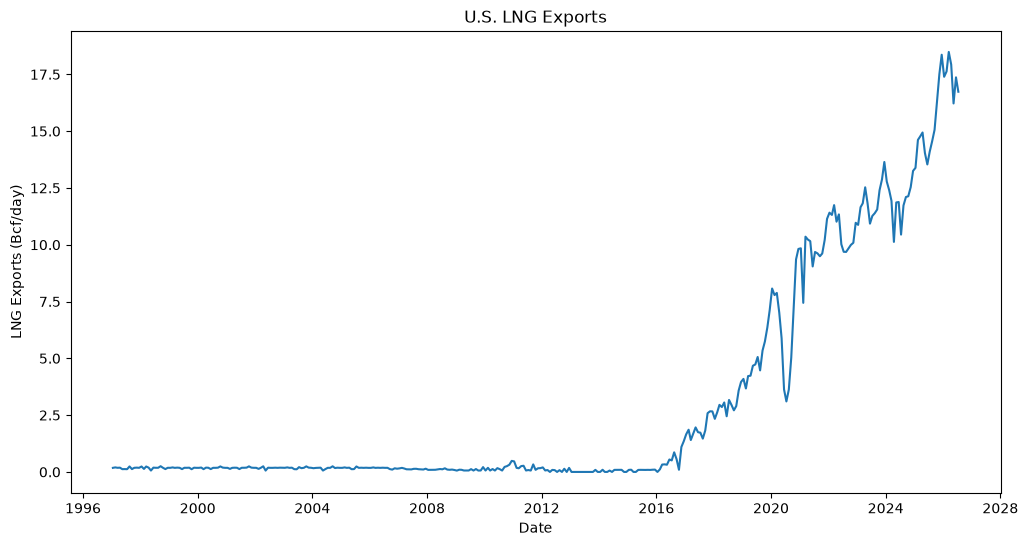

In [15]:
plt.figure(figsize=(12, 6))

plt.plot(exports["Date"], exports["lng_exports_bcfd"])

plt.title("U.S. LNG Exports")
plt.xlabel("Date")
plt.ylabel("LNG Exports (Bcf/day)")

plt.show()